# Project - User Retention Retail Analysis
In this project, we will answer the questions below
- How can a business build a loyal user or customer base—and even retain those customers when the going gets tough?
- What role does Python analysis actually play in relation to users or customers?
  
All of the above questions can be answered using User Retention Analysis

**Dataset source:** https://www.kaggle.com/datasets/minalchoudhary/online-retail-dataset

# Impor packages

In [ ]:
# import all packages
import pandas as pd
import numpy as np
import datetime as dt
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import missingno as msno
import pandas as pd
import seaborn as sns
from scipy import stats

os.getcwd()

'/content'

# Import data from CSV to DataFrame

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Analysis/MySkill Project/online_retail_II.xlsx.csv', header=0, encoding='latin1')
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,09-12-2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,09-12-2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,09-12-2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,09-12-2011 12:50,4.95,12680.0,France


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  object 
 1   StockCode    541910 non-null  object 
 2   Description  540456 non-null  object 
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  object 
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


# Data Cleaning

In [ ]:
df_clean = df.copy()
# convert PurchaseDate column to datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], format='%d-%m-%Y %H:%M')

In [ ]:
# make year_month column
df_clean['year_month'] = df_clean['InvoiceDate'].dt.to_period('M')

In [ ]:
# check null data
df_clean.isnull().sum()

,0
Invoice,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
Price,0
Customer ID,135080
Country,0
year_month,0


## Handling Description null data

In [ ]:
# make StockCode mapping to Description
product_dict = (
    df_clean.dropna(subset=["Description"])
    .set_index("StockCode")["Description"]
    .to_dict()
)

# fill null Description
df_clean["Description"] = df_clean["Description"].fillna(df["StockCode"].map(product_dict))

# delete the rest of null data at Description
df_clean = df_clean.dropna(subset=["Description"])

## Handling Customer ID null data

In [ ]:
# calculate null data percentage
print((df_clean.isnull().sum() / len(df)) * 100)

Invoice         0.000000
StockCode       0.000000
Description     0.000000
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    24.905981
Country         0.000000
year_month      0.000000
dtype: float64


<Figure size 1000x600 with 0 Axes>

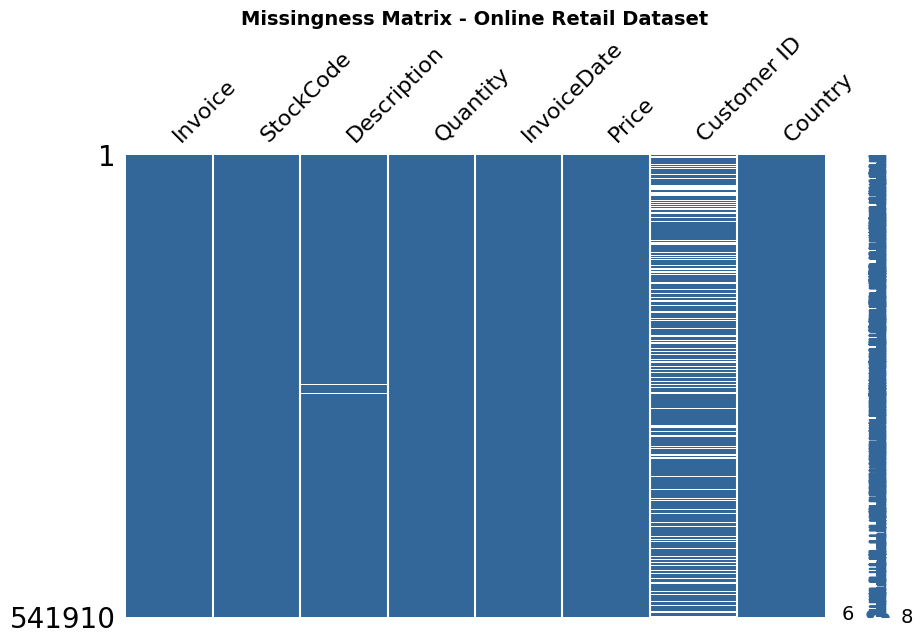

<Figure size 800x600 with 0 Axes>

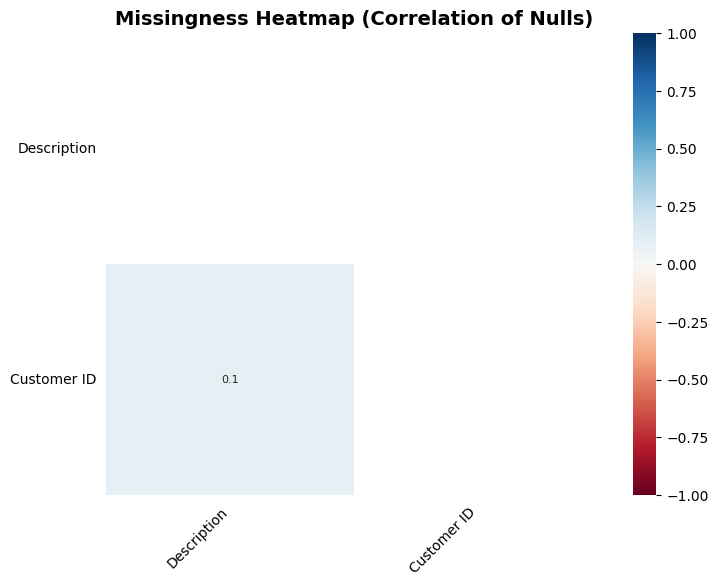

In [ ]:
# Matrix visualize the null position
plt.figure(figsize=(10, 6))
msno.matrix(df, figsize=(10, 6), color=(0.2, 0.4, 0.6))
plt.title(
    "Missingness Matrix - Online Retail Dataset", fontsize=14, fontweight="bold"
)
plt.show()

# Heatmap to check if null column corelated to other null column
plt.figure(figsize=(8, 6))
msno.heatmap(df, figsize=(8, 6), fontsize=10)
plt.title(
    "Missingness Heatmap (Correlation of Nulls)", fontsize=14, fontweight="bold"
)
plt.show()

In [ ]:
# Make a biner column converter for Customer ID, 1 for null, 0 for non-null
df_clean["CustomerID_missing"] = df_clean["Customer ID"].isnull().astype(int)

# Make sure if the null data corelated with 'Country' column
print(
    df_clean.groupby("Country")["CustomerID_missing"]
    .mean()
    .sort_values(ascending=False)
)

Country
Hong Kong               1.000000
Unspecified             0.452915
United Kingdom          0.269473
Israel                  0.158249
Bahrain                 0.105263
EIRE                    0.086750
Switzerland             0.062438
Portugal                0.025675
France                  0.007712
Canada                  0.000000
Australia               0.000000
Brazil                  0.000000
Belgium                 0.000000
Austria                 0.000000
Finland                 0.000000
European Community      0.000000
Greece                  0.000000
Germany                 0.000000
Denmark                 0.000000
Czech Republic          0.000000
Channel Islands         0.000000
Cyprus                  0.000000
Lebanon                 0.000000
Japan                   0.000000
Italy                   0.000000
Iceland                 0.000000
Norway                  0.000000
Lithuania               0.000000
Netherlands             0.000000
Malta                   0.000000
Sa

In [ ]:
df_clean.isnull().sum()

,0
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,134968
Country,0
year_month,0
CustomerID_missing,0


## Delete Negative Quantity

In [ ]:
df_clean['Quantity'].astype(int)

,Quantity
0,6
1,6
2,8
3,6
4,6
...,...
541905,6
541906,4
541907,4
541908,3


In [ ]:
# Show Quantity less than 0 where is represent cancelled
print(df_clean.loc[df['Quantity'] < 0, ['Description', 'Quantity']])

                             Description  Quantity
141                             Discount        -1
154      SET OF 3 COLOURED  FLYING DUCKS        -1
235       PLASTERS IN TIN CIRCUS PARADE        -12
236     PACK OF 12 PINK PAISLEY TISSUES        -24
237     PACK OF 12 BLUE PAISLEY TISSUES        -24
...                                  ...       ...
540449   ZINC T-LIGHT HOLDER STARS SMALL       -11
541541                            Manual        -1
541715        VICTORIAN SEWING BOX LARGE        -5
541716  HANGING HEART JAR T-LIGHT HOLDER        -1
541717     36 PENCILS TUBE RED RETROSPOT        -5

[10527 rows x 2 columns]


In [ ]:
df_clean = df_clean[df_clean['Quantity'] > 0].copy()

In [ ]:
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year_month,CustomerID_missing
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0


## Delete outlier

In [ ]:
# Delete outlier
df_clean = df_clean[(np.abs(stats.zscore(df_clean[['Price']]))<3).all(axis=1)]
df_clean = df_clean.reset_index(drop=True)
df_clean

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year_month,CustomerID_missing
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,0
...,...,...,...,...,...,...,...,...,...,...
530585,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011-12,0
530586,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011-12,0
530587,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011-12,0
530588,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011-12,0


## Convert some of data type

In [ ]:
df_clean['Customer ID'] = df_clean['Customer ID'].astype(str)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530590 entries, 0 to 530589
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Invoice             530590 non-null  object        
 1   StockCode           530590 non-null  object        
 2   Description         530590 non-null  object        
 3   Quantity            530590 non-null  int64         
 4   InvoiceDate         530590 non-null  datetime64[ns]
 5   Price               530590 non-null  float64       
 6   Customer ID         530590 non-null  object        
 7   Country             530590 non-null  object        
 8   year_month          530590 non-null  period[M]     
 9   CustomerID_missing  530590 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2), object(5), period[M](1)
memory usage: 40.5+ MB


## Use only 2011 data

In [ ]:
# Filter df_user_monthly to only include transactions from 2011
df_clean = df_clean[df_clean['year_month'].dt.year == 2011].copy()

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 488974 entries, 41616 to 530589
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Invoice             488974 non-null  object        
 1   StockCode           488974 non-null  object        
 2   Description         488974 non-null  object        
 3   Quantity            488974 non-null  int64         
 4   InvoiceDate         488974 non-null  datetime64[ns]
 5   Price               488974 non-null  float64       
 6   Customer ID         488974 non-null  object        
 7   Country             488974 non-null  object        
 8   year_month          488974 non-null  period[M]     
 9   CustomerID_missing  488974 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2), object(5), period[M](1)
memory usage: 41.0+ MB


# Creating a user retention cohort

## Aggregate transaction data into a summary of total transactions/orders for each user each month

In [ ]:
# Make sure that empty values are converted back to NaN
df_clean['Customer ID'] = df_clean['Customer ID'].replace(['nan', 'None', '', 'NaT'], np.nan)

# Create a specific subset for retention analysis (exclude those with a null Customer ID)
df_cohort = df_clean.dropna(subset=['Customer ID']).copy()

In [ ]:
df_user_monthly = df_clean.groupby(['Customer ID','year_month'], as_index=False).agg(order_cnt=('Customer ID','count'))
df_user_monthly

,Customer ID,year_month,order_cnt
0,12346.0,2011-01,1
1,12347.0,2011-01,29
2,12347.0,2011-04,24
3,12347.0,2011-06,18
4,12347.0,2011-08,22
...,...,...,...
12149,18283.0,2011-10,40
12150,18283.0,2011-11,219
12151,18283.0,2011-12,50
12152,18287.0,2011-05,29


## Create a column for user cohorts; for example, the cohort for the first month of transactions

In [ ]:
df_user_monthly['cohort'] = df_user_monthly.groupby('Customer ID')['year_month'].transform('min')
df_user_monthly

,Customer ID,year_month,order_cnt,cohort
0,12346.0,2011-01,1,2011-01
1,12347.0,2011-01,29,2011-01
2,12347.0,2011-04,24,2011-01
3,12347.0,2011-06,18,2011-01
4,12347.0,2011-08,22,2011-01
...,...,...,...,...
12149,18283.0,2011-10,40,2011-01
12150,18283.0,2011-11,219,2011-01
12151,18283.0,2011-12,50,2011-01
12152,18287.0,2011-05,29,2011-05


## Calculate the number of months between the transaction month and the month of the first transaction, and add 1 to that number.

In [ ]:
from operator import attrgetter

df_user_monthly['period_num'] = (df_user_monthly['year_month'] - df_user_monthly['cohort']).apply(attrgetter('n')) + 1
df_user_monthly

,Customer ID,year_month,order_cnt,cohort,period_num
0,12346.0,2011-01,1,2011-01,1
1,12347.0,2011-01,29,2011-01,1
2,12347.0,2011-04,24,2011-01,4
3,12347.0,2011-06,18,2011-01,6
4,12347.0,2011-08,22,2011-01,8
...,...,...,...,...,...
12149,18283.0,2011-10,40,2011-01,10
12150,18283.0,2011-11,219,2011-01,11
12151,18283.0,2011-12,50,2011-01,12
12152,18287.0,2011-05,29,2011-05,1


## A pivot table with a cohort index, a column representing the number of months, and values representing the number of unique users

In [ ]:
df_cohort_pivot = pd.pivot_table(df_user_monthly, index='cohort', columns='period_num', values='Customer ID', aggfunc=pd.Series.nunique)
df_cohort_pivot

period_num,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,
2011-01,740.0,261.0,318.0,283.0,339.0,311.0,290.0,285.0,325.0,309.0,380.0,189.0
2011-02,496.0,116.0,122.0,169.0,155.0,135.0,151.0,162.0,153.0,181.0,61.0,NaN
2011-03,538.0,87.0,144.0,119.0,123.0,101.0,153.0,130.0,162.0,57.0,NaN,NaN
2011-04,361.0,84.0,79.0,85.0,76.0,85.0,88.0,107.0,31.0,NaN,NaN,NaN
2011-05,318.0,58.0,56.0,58.0,70.0,76.0,88.0,31.0,NaN,NaN,NaN,NaN
2011-06,268.0,47.0,41.0,68.0,60.0,91.0,26.0,NaN,NaN,NaN,NaN,NaN
2011-07,211.0,38.0,47.0,49.0,57.0,29.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,185.0,38.0,47.0,46.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-09,315.0,76.0,100.0,39.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
cohort_size = df_cohort_pivot.iloc[:, 0]
cohort_size

,1
cohort,
2011-01,740.0
2011-02,496.0
2011-03,538.0
2011-04,361.0
2011-05,318.0
2011-06,268.0
2011-07,211.0
2011-08,185.0
2011-09,315.0


In [ ]:
df_retention_cohort = df_cohort_pivot.divide(cohort_size, axis=0)
df_retention_cohort

period_num,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,
2011-01,1.0,0.352703,0.429730,0.382432,0.458108,0.420270,0.391892,0.385135,0.439189,0.417568,0.513514,0.255405
2011-02,1.0,0.233871,0.245968,0.340726,0.312500,0.272177,0.304435,0.326613,0.308468,0.364919,0.122984,NaN
2011-03,1.0,0.161710,0.267658,0.221190,0.228625,0.187732,0.284387,0.241636,0.301115,0.105948,NaN,NaN
2011-04,1.0,0.232687,0.218837,0.235457,0.210526,0.235457,0.243767,0.296399,0.085873,NaN,NaN,NaN
2011-05,1.0,0.182390,0.176101,0.182390,0.220126,0.238994,0.276730,0.097484,NaN,NaN,NaN,NaN
2011-06,1.0,0.175373,0.152985,0.253731,0.223881,0.339552,0.097015,NaN,NaN,NaN,NaN,NaN
2011-07,1.0,0.180095,0.222749,0.232227,0.270142,0.137441,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,1.0,0.205405,0.254054,0.248649,0.135135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-09,1.0,0.241270,0.317460,0.123810,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


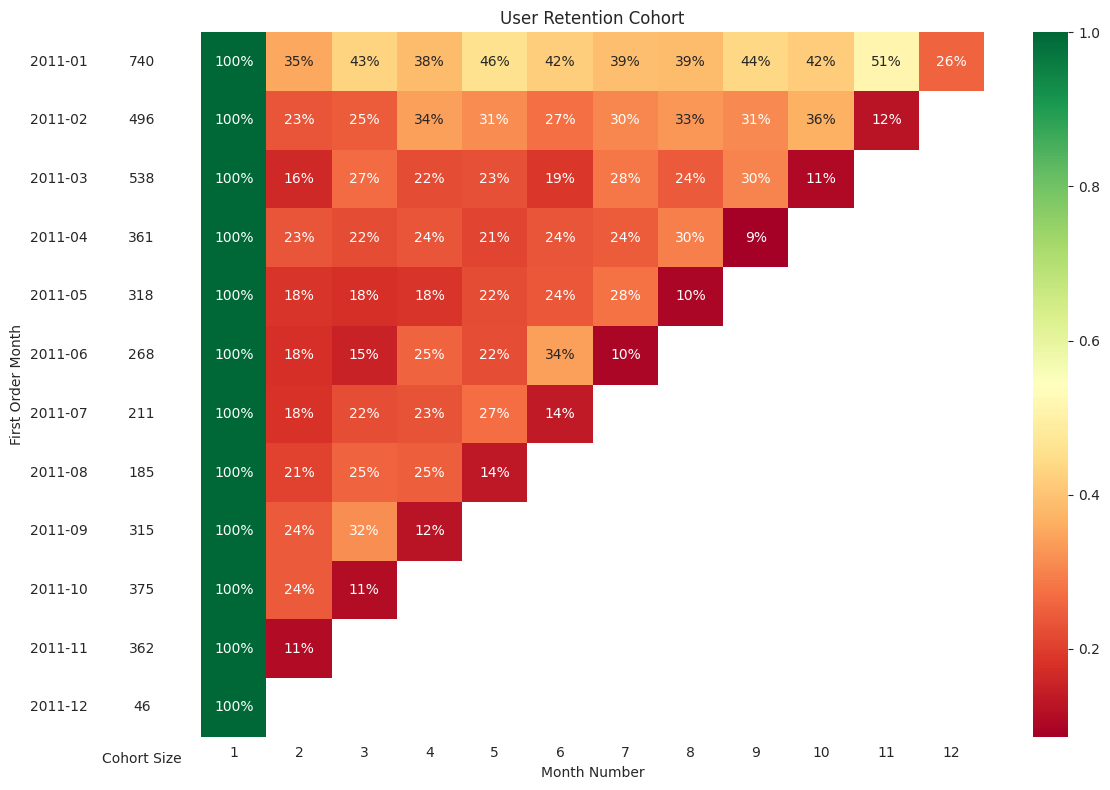

In [ ]:
with sns.axes_style('white'):

    fig, ax = plt.subplots(1, 2, figsize=(12, 8), sharey=True, gridspec_kw={'width_ratios':[1, 11]})

    # user retention cohort
    sns.heatmap(df_retention_cohort, annot=True, fmt='.0%', cmap='RdYlGn', ax=ax[1])
    ax[1].set_title('User Retention Cohort')
    ax[1].set(xlabel='Month Number', ylabel='')

    # cohort size
    df_cohort_size = pd.DataFrame(cohort_size)
    white_cmap = mcolors.ListedColormap(['white'])
    sns.heatmap(df_cohort_size, annot=True, cbar=False, fmt='g', cmap=white_cmap, ax=ax[0])
    ax[0].tick_params(bottom=False)
    ax[0].set(xlabel='Cohort Size', ylabel='First Order Month', xticklabels=[])

    fig.tight_layout()